[Projet CHPS1001](../README.md) · [Mesures de la campagne](../results/romeo/README.md) · [Rapport PDF](../report/rapport.pdf)

# Profilage de NvPD sur ROMEO

Deux séquences de longueurs $m$ et $n$ définissent $mn$ cellules intérieures de distance d’édition. NvPD les remplit ligne par ligne. À chaque nouvelle ligne, les fils se synchronisent avant de lire les scores précédents. Quand les lignes deviennent longues, ces lectures font intervenir plusieurs niveaux de cache. Ce carnet compare d’abord les algorithmes, puis examine ces coûts sur CPU et GPU. Les dernières expériences portent sur le portage Kokkos, la répartition MPI et deux assemblages du chromosome 21.

**Résultats.** Sur un cœur EPYC, vectoriser la boucle accélère le calcul de 5,85 fois pour 256 × 1 000 000 cases. Sur le GH200, les tuiles à largeur adaptative ramènent le temps chaud de 5,14 à 3,62 s sur une paire d’un million de bases à 2 % d’erreur. Sur deux nœuds, la distribution des 2 016 alignements de phages accélère la matrice de 1,42 fois par rapport à un nœud.

La première figure compare les exécutables de la campagne initiale sur un **même FASTA**. Les essais de profilage comparent les variantes avant et après modification sur un **même jeu d’entrées**, avec leur propre compilation. Les temps mesurés dans deux campagnes différentes ne servent pas au calcul des gains A/B.

Les mesures proviennent de ROMEO, sauf celles de la section 12, effectuées sur un Apple M1 Pro. Les figures se recalculent à partir des CSV du projet. Les sorties sont enregistrées dans le carnet. Pour les recalculer depuis la racine avec Python 3.11, installer les dépendances puis exécuter `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/profil_nvpd.ipynb`. L’exécution lit les CSV fournis et écrit les figures dans `figures/`. [Dépendances Python](requirements.txt)

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

nv_cwd = Path.cwd().resolve()
ROOT = nv_cwd if (nv_cwd / "CMakeLists.txt").is_file() else nv_cwd.parent
sys.path.insert(0, str(ROOT / "notebooks"))
import ct_plot
from ct_plot import COLORS, GUIDE, label_panels, legend_above

ct_plot.use_style()
RES = ROOT / "results"
PROF = RES / "profile"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.options.display.float_format = "{:.3g}".format

def nv_save(figure, name):
    figure.savefig(FIG / (name + ".png"), dpi=150, facecolor="white")
    plt.show()

def nv_csv(path):
    return pd.read_csv(path, keep_default_na=False)

def nv_band(axis, series, color, label, marker="o"):
    # Pour chaque abscisse, un point médian et l'étendue des mesures.
    summary = series.groupby(level=0).agg(["median", "min", "max"])
    errors = [summary["median"] - summary["min"], summary["max"] - summary["median"]]
    axis.errorbar(summary.index, summary["median"], yerr=errors, marker=marker, color=color,
                  capsize=2, label=label, markeredgecolor="0.23")

## 1. Coût d’un alignement exact

L’alignement est global. Une insertion, une suppression ou une substitution coûte une unité. Deux symboles IUPAC doivent être identiques pour donner une correspondance. Sur CPU, edlib calcule la distance avec des opérations bit-parallèles. WFA2-lib utilise les fronts d’onde en mode distance d’édition exacte, sans heuristique. L’implémentation WFA-GPU décrite par Aguado-Puig et coll. est une autre bibliothèque. La série GPU mesurée ici exécute NvPD. [NvPD, Sadiq et coll.](https://doi.org/10.1007/s10586-019-02962-w) · [edlib, Šošić et Šikić](https://doi.org/10.1093/bioinformatics/btw753) · [WFA, Marco-Sola et coll.](https://doi.org/10.1093/bioinformatics/btaa777) · [WFA-GPU, Aguado-Puig et coll.](https://doi.org/10.1109/ACCESS.2022.3182714)

La première campagne a produit 60 paires synthétiques avec une graine maîtresse de 2026. À un million de bases, la programmation dynamique dense sur CPU traite une paire par taux. Les deux bibliothèques et le GPU en traitent cinq. Le temps par paire commence après la lecture FASTA et couvre l’allocation ainsi que le retour du coût. Pour CUDA, le premier appel inclut l’initialisation du contexte.

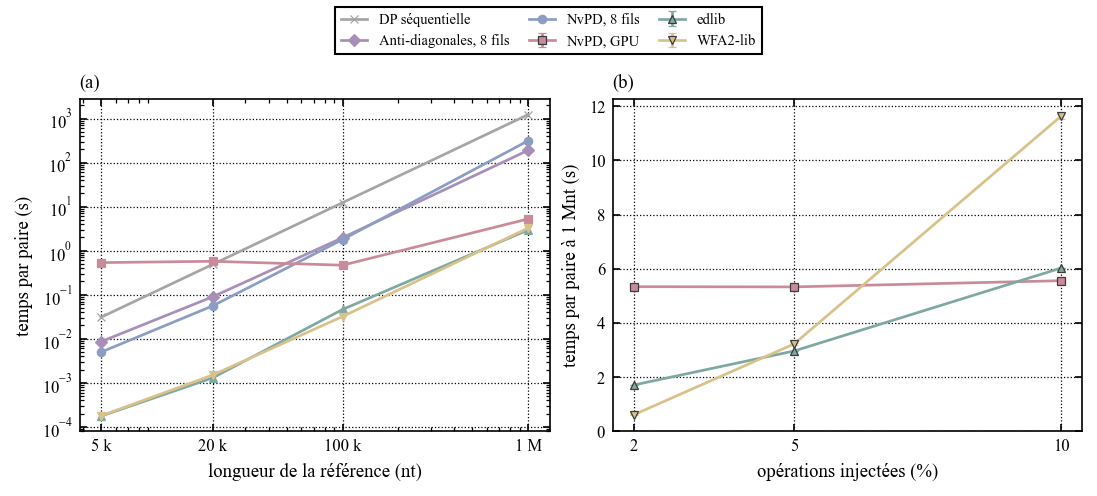

In [2]:
# Durée selon la longueur et le taux d'erreur (results/romeo/{cpu,gpu}-*.csv).
nv_runs = pd.concat([nv_csv(path) for path in sorted((RES / "romeo").glob("*-*.csv"))],
                    ignore_index=True)
assert nv_runs.status.eq("ok").all() and (nv_runs.seconds > 0).all()
assert nv_runs.groupby("input_sha256").distance.nunique().eq(1).all()
nv_methods = {
    "seq": ("DP séquentielle", COLORS[4], "x"), "diagonal": ("Anti-diagonales, 8 fils", COLORS[5], "D"),
    "nvpd-omp": ("NvPD, 8 fils", COLORS[0], "o"), "nvpd-cuda": ("NvPD, GPU", COLORS[1], "s"),
    "edlib": ("edlib", COLORS[2], "^"), "wfa2": ("WFA2-lib", COLORS[3], "v"),
}
nv_selected = nv_runs[nv_runs.threads.eq(8) | ~nv_runs.algorithm.isin(["diagonal", "nvpd-omp"])]
# Une seule valeur par paire et méthode, même quand une campagne répète sa mesure.
nv_pair = (nv_selected.groupby(["length", "rate", "rep", "algorithm", "input_sha256"], as_index=False)
           .agg(seconds=("seconds", "median"), distance=("distance", "first")))
nv_fig, nv_ax = plt.subplots(1, 2, figsize=(7.2, 3.2))
for nv_alg, (nv_name, nv_color, nv_marker) in nv_methods.items():
    nv_sub = nv_pair[nv_pair.algorithm.eq(nv_alg)]
    nv_len = nv_sub[nv_sub.rate.eq(.05) & nv_sub.rep.eq(1)].sort_values("length")
    assert nv_len.length.tolist() == [5000, 20000, 100000, 1000000]
    nv_ax[0].plot(nv_len.length, nv_len.seconds, marker=nv_marker, color=nv_color, label=nv_name)
    if nv_alg in ("nvpd-cuda", "edlib", "wfa2"):
        nv_err = nv_sub[nv_sub.length.eq(1000000)].set_index("rate")
        assert nv_err.groupby(level=0).size().eq(5).all()
        nv_err.index = nv_err.index * 100
        nv_band(nv_ax[1], nv_err.seconds, nv_color, nv_name, nv_marker)
nv_ax[0].set(xscale="log", yscale="log", xlabel="longueur de la référence (nt)", ylabel="temps par paire (s)")
nv_ax[0].set_xticks([5000, 20000, 100000, 1000000], ["5 k", "20 k", "100 k", "1 M"])
nv_ax[1].set(xlabel="opérations injectées (%)", ylabel="temps par paire à 1 Mnt (s)", ylim=(0, None))
nv_ax[1].set_xticks([2, 5, 10])
label_panels(nv_ax)
legend_above(nv_fig, nv_ax, ncol=3)
nv_save(nv_fig, "01_temps_distance")

*Figure 001.* Temps d’un alignement de coût seul. (a) Première paire pour chaque longueur à 5 % d’erreur. Les deux axes sont logarithmiques. (b) Cinq paires par taux à un million de bases. Le point marque la médiane et la barre relie le minimum au maximum.

À un million de bases, WFA2-lib passe de 0,61 s à 11,64 s entre 2 et 10 % d’opérations injectées. Sur les mêmes groupes, edlib passe de 1,71 à 6,03 s, NvPD sur GPU de 5,34 à 5,56 s. NvPD parcourt toute la matrice. Les fronts de WFA grandissent avec la distance optimale. Le taux décrit les opérations tirées par le générateur, dont le nombre peut dépasser la distance minimale.

**Synthèse.** Sur ces cinq paires par taux, la méthode la plus rapide change avec la divergence. Les médianes les plus basses sont celles de WFA2-lib à 2 %, d’edlib à 5 % et de NvPD sur GPU à 10 %.

<sub>Code : [générateur](../scripts/synthetic.py), [comparaison exacte](../src/baselines.cpp), [chronométrage](../bench/run.py), [mesures brutes](../results/romeo/).</sub>

## 2. Répartir les colonnes sur les cœurs de l’EPYC

Soit $T_p(m,n)$ le temps médian de trois essais de NvPD sur $p$ cœurs. À taille fixe, l’accélération vaut $S_p=T_1(m,n)/T_p(m,n)$, l’efficacité $S_p/p$. À travail fixe par cœur, le calcul garde 4 096 lignes et multiplie le nombre de colonnes par $p$. L’efficacité faible vaut alors $T_1(4096,4096)/T_p(4096,4096p)$. Les deux expériences gardent le même nombre de barrières de lignes lorsque $p$ varie, mais seule la seconde conserve le nombre de cases à traiter par cœur. [Cornell, mesures de passage à l’échelle](https://cvw.cac.cornell.edu/parallel/efficiency/scaling) · [Amdahl, 1967](https://doi.org/10.1145/1465482.1465560)

Les essais emploient la même variante à l’intérieur de chaque courbe, des fils attachés aux cœurs avec OpenMP et une phase de chauffe. Chaque processus vérifie sa distance et l’empreinte de ses entrées contre la référence avant la mise en commun des résultats. V1 utilise un index d’entiers sur quatre octets et une boucle vectorisable. V2 essaie de représenter les écarts de l’index sur un octet. La section suivante détaille leur comparaison.

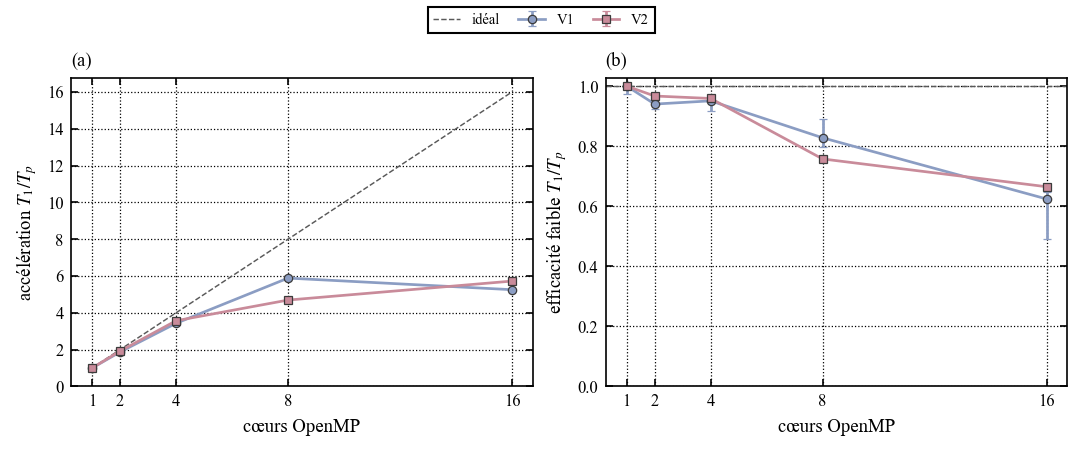

In [3]:
# Taille fixe et travail fixe par cœur, pour V1 et V2 (results/profile/cpu/scaling.csv).
sc_raw = nv_csv(PROF / "cpu/scaling.csv")
assert sc_raw.distance.eq(sc_raw.reference_distance).all()
sc_p = [1, 2, 4, 8, 16]
assert set(sc_raw.threads) == set(sc_p)
assert sc_raw.groupby(["variant", "study", "threads"]).trial.nunique().eq(3).all()
sc_fig, sc_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for sc_i, sc_v in enumerate(["v1", "v2"]):
    sc_rows = sc_raw[sc_raw.variant.eq(sc_v)].set_index("threads")
    for sc_j, sc_study in enumerate(["strong", "weak"]):
        sc_g = sc_rows[sc_rows.study.eq(sc_study)]
        if sc_study == "strong":
            assert sc_g.input_fnv64.nunique() == 1 and sc_g.cells.eq(20000**2).all()
        else:
            assert (sc_g.cells / sc_g.index == 4096**2).all()
        sc_t1 = sc_g.loc[1, "seconds"].median()
        nv_band(sc_ax[sc_j], sc_t1 / sc_g.seconds, COLORS[sc_i], sc_v.upper(), marker="os"[sc_i])
sc_ax[0].plot(sc_p, sc_p, **GUIDE, label="idéal")
sc_ax[0].set(xlabel="cœurs OpenMP", ylabel=r"accélération $T_1/T_p$")
sc_ax[1].axhline(1, **GUIDE, label="idéal")
sc_ax[1].set(xlabel="cœurs OpenMP", ylabel=r"efficacité faible $T_1/T_p$")
for sc_axis in sc_ax:
    sc_axis.set_xticks(sc_p)
    sc_axis.set_ylim(bottom=0)
label_panels(sc_ax)
legend_above(sc_fig, sc_ax, ncol=3)
nv_save(sc_fig, "02_echelle_cpu")

*Figure 002.* Passage à l’échelle sur un nœud EPYC. (a) Taille fixe de 20 000 × 20 000 cases. (b) 16 777 216 cases par cœur, de un à seize cœurs. Le trait pointillé donne le cas idéal. Les barres montrent l’étendue des trois mesures avec un même temps médian à un cœur au numérateur.

Sur le carré de 20 000 bases, V1 passe de 164,4 ms sur un cœur à 27,9 ms sur huit, puis remonte à 31,3 ms sur seize. Son efficacité forte atteint 74 % sur huit cœurs et 33 % sur seize. À huit cœurs, NvPD met à jour les 400 millions de cases à raison de 14,3 milliards de cases par seconde (GCUPS). À travail fixe par cœur, V1 passe de 8,57 à 13,73 ms entre un et seize cœurs, soit 62,4 % d’efficacité faible. À seize cœurs, V2 atteint 66,5 % en efficacité faible.

**Synthèse.** Pour V1 et ce carré, huit cœurs donnent le temps le plus court parmi les cinq nombres de cœurs testés. La forme rectangulaire du test faible change la largeur des lignes et le volume de l’index. Son efficacité ne se transpose pas aux paires carrées.

<sub>Code : [pilote C++](../bench/profile_cpu_driver.cpp), [essais et oracle](../bench/profile_cpu.py), [placement Slurm](../bench/profile_cpu.sbatch), [mesures](../results/profile/cpu/scaling.csv).</sub>

## 3. Choisir une boucle de calcul sur CPU

La version initiale utilise la dernière occurrence $k$ d’une lettre pour choisir le prédécesseur. Pour la case $(i,j)$, $k$ est la dernière position de la lettre $a_i$ dans $b_1,\dots,b_j$ et vaut zéro si elle est absente. Sur les colonnes intérieures, V1 calcule

$$D_{i,j}=\min\!\left(1+\min(D_{i-1,j-1},D_{i-1,j}),\,D_{i-1,\max(0,k-1)}+j-k\right).$$

Les bords valent $D_{i,0}=i$ et $D_{0,j}=j$. La formule lit uniquement la ligne précédente. Quand $k=j$, le second candidat reprend la diagonale sans coût. Quand $k=0$, il vaut $i-1+j$, une borne supérieure de la distance. Cette forme permet à OpenMP de vectoriser les colonnes. V2 reprend cette boucle et stocke les écarts $j-k$ sur un octet lorsque le maximum reste inférieur à 256. Si un écart est plus grand, V2 garde les entiers de quatre octets. Les scores restent entiers dans les trois versions. Les appels NvPD incluent la construction de l’index de dernières occurrences, l’allocation et les mises à jour de la matrice. Chaque paire de variantes utilise la même compilation, avec `-O3 -march=native -fopenmp`. À chaque répétition, le pilote mélange l’ordre des cas et alterne A puis B ou B puis A.

Les trois géométries isolent deux effets. Le carré de 20 000 × 20 000 distribue de nombreuses lignes de taille modérée. Les rectangles de 256 × 1 000 000 et de 64 × 4 194 304 contiennent des lignes de plus en plus longues et peu de barrières. Le second rectangle donne à l’index une largeur de plus de quatre millions de colonnes pour étudier son comportement dans les caches.

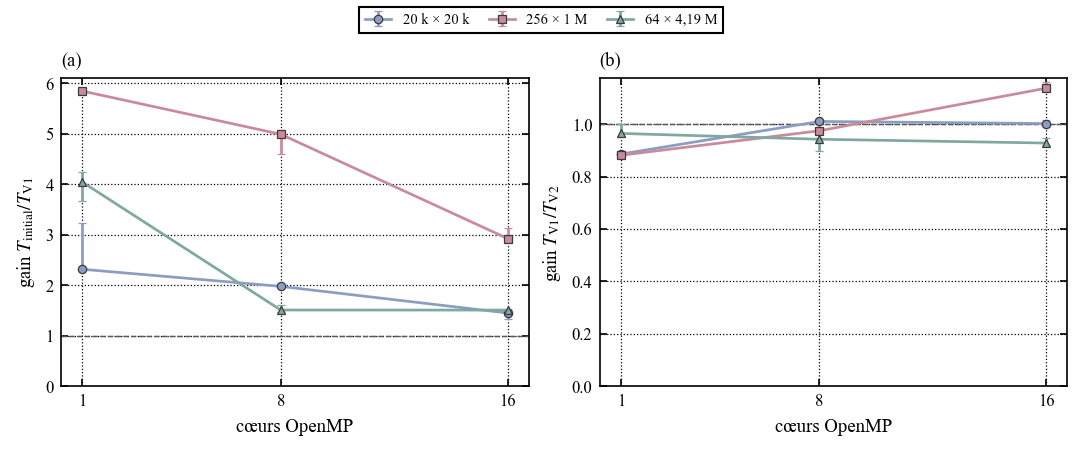

In [4]:
# Gains par étape à entrées et placement identiques (results/profile/cpu/ab.csv).
ab_raw = nv_csv(PROF / "cpu/ab.csv")
assert ab_raw.distance.eq(ab_raw.reference_distance).all()
assert ab_raw.groupby("case").input_fnv64.nunique().eq(1).all()
assert ab_raw.groupby(["comparison", "case", "threads", "trial"]).cpu_ids.nunique().eq(1).all()
assert ab_raw.groupby("case").max_gap.max().lt(256).all()
ab_cases = {"square": "20 k × 20 k", "wide": "256 × 1 M", "over_l3": "64 × 4,19 M"}
ab_fig, ab_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for ab_i, (ab_a, ab_b) in enumerate([("baseline", "v1"), ("v1", "v2")]):
    ab_sub = ab_raw[ab_raw.comparison.eq(ab_a + "-" + ab_b)]
    ab_time = ab_sub.pivot(index=["case", "threads", "trial"], columns="variant", values="seconds")
    assert ab_time.notna().all().all() and (ab_time > 0).all().all()
    ab_rat = ab_time[ab_a] / ab_time[ab_b]
    for ab_k, (ab_case, ab_name) in enumerate(ab_cases.items()):
        nv_band(ab_ax[ab_i], ab_rat.xs(ab_case).droplevel("trial"), COLORS[ab_k], ab_name, marker="os^"[ab_k])
    ab_ax[ab_i].axhline(1, **GUIDE)
    ab_ax[ab_i].set(xlabel="cœurs OpenMP", ylim=(0, None))
    ab_ax[ab_i].set_xticks([1, 8, 16])
ab_ax[0].set_ylabel(r"gain $T_\mathrm{initial}/T_\mathrm{V1}$")
ab_ax[1].set_ylabel(r"gain $T_\mathrm{V1}/T_\mathrm{V2}$")
label_panels(ab_ax)
legend_above(ab_fig, ab_ax, ncol=3)
nv_save(ab_fig, "03_variantes_cpu")

*Figure 003.* Gains appariés sur un nœud EPYC. (a) Effet de la réécriture pour vectorisation. (b) Effet supplémentaire de l’index compact. Un point au-dessus de un favorise la nouvelle variante. Les points et les barres donnent la médiane et l’étendue des trois rapports appariés.

Sur le carré, V1 réduit le temps d’un facteur 2,32 à un cœur, 1,98 à huit et 1,45 à seize. Pour le rectangle de 256 lignes, le gain atteint 5,85 à un cœur. Le gain apparié de V2 par rapport à V1 atteint 1,14 sur ce rectangle à seize cœurs, puis tombe à 0,93 sur le rectangle de 64 lignes. Sur le carré à un cœur, il vaut 0,89.

**Synthèse.** V1 accélère les neuf configurations par rapport à la version initiale. C’est la boucle retenue. V2 diminue la mémoire de l’index, mais augmente le temps dans plusieurs configurations.

<sub>Code : [NvPD OpenMP](../src/dp.cpp), [protocole V2 et tag `experiment/compact-index`](../bench/profile_cpu.md), [comparaison A/B](../bench/profile_cpu.py), [mesures](../results/profile/cpu/ab.csv).</sub>

## 4. Mémoire allouée et événements des caches

Pour un alphabet de quatre lettres, les deux lignes de scores occupent $2(n+1)$ entiers. L’index des dernières occurrences en occupe $4(n+1)$. V1 occupe donc $24(n+1)$ octets. Si la conversion réussit, V2 occupe $12(n+1)$ octets pendant la boucle. La conversion conserve temporairement deux représentations de l’index. Une ligne lue pour une lettre donnée ne consulte qu’une des quatre lignes de cet index. Le pic RSS mesure le maximum de mémoire résidente du **processus entier**, y compris les chaînes, les autres allocations et la phase de chauffe.

Les compteurs en espace utilisateur couvrent un appel après chauffe, pour toute l’équipe OpenMP. Le pilote ouvre et ferme la fenêtre de mesure avec `perf stat --control`. Un compteur non pris en charge représente une mesure manquante. Les événements génériques dépendent du PMU et ne suffisent pas à déduire un débit DRAM. Les écarts maximaux, de 31 à 48 selon la forme, permettent à V2 d’utiliser des octets sur les trois cas. [Linux perf, manuel de perf-stat](https://man7.org/linux/man-pages/man1/perf-stat.1.html)

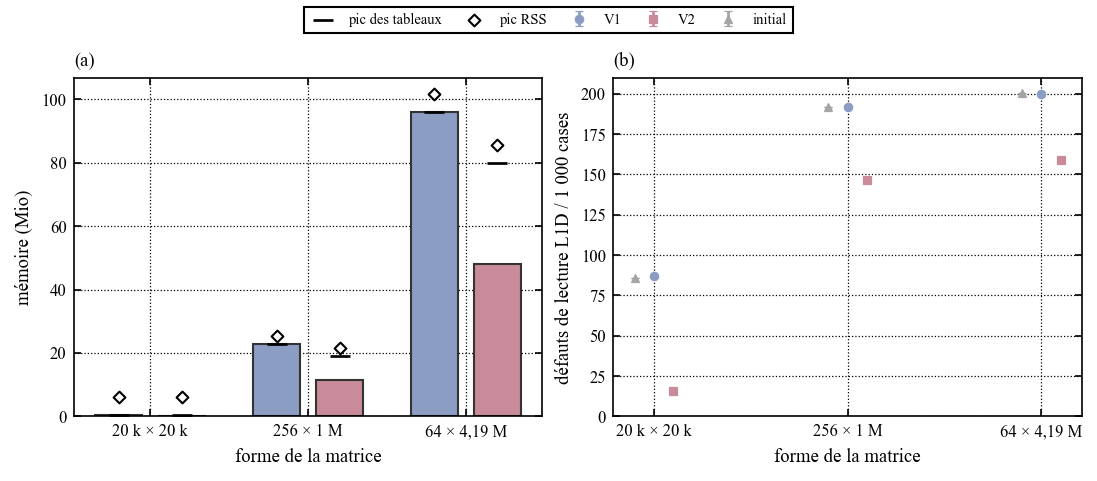

In [5]:
# Espace de travail et événements L1D, huit cœurs (results/profile/cpu/{ab,counters}.csv).
me_perf = nv_csv(PROF / "cpu/counters.csv")
assert me_perf.distance.eq(me_perf.reference_distance).all()
assert me_perf.running_pct.eq(100).all()
me_perf["event"] = me_perf.event.str.removesuffix(":u")
me_perf["count"] = pd.to_numeric(me_perf.value, errors="coerce")
me_perf["per_cell"] = me_perf["count"] / (me_perf.m * me_perf.n)
me_fig, me_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
me_x = np.arange(len(ab_cases))
me_rows = ab_raw[(ab_raw.threads == 8) & ab_raw.comparison.eq("v1-v2")]
for me_i, me_v in enumerate(["v1", "v2"]):
    me_g = me_rows[me_rows.variant.eq(me_v)].groupby("case")
    me_scores = me_g.dp_bytes.first().reindex(ab_cases)
    me_index = me_g.mit_bytes.first().reindex(ab_cases)
    me_peak = me_g.workspace_peak_bytes.first().reindex(ab_cases)
    me_rss = me_g.peak_rss_kib.max().reindex(ab_cases) / 1024
    me_pos = me_x + .2 * (2*me_i - 1)
    me_ax[0].bar(me_pos, (me_scores + me_index) / 2**20, width=.30, color=COLORS[me_i],
                 edgecolor="0.2", label=me_v.upper(), zorder=2)
    me_ax[0].scatter(me_pos, me_peak / 2**20, marker="_", s=100, color="black",
                     zorder=3, label="pic des tableaux" if me_i == 0 else None)
    me_ax[0].scatter(me_pos, me_rss, marker="D", s=16, facecolor="white", edgecolor="black",
                     zorder=3, label="pic RSS" if me_i == 0 else None)
for me_k, me_v in enumerate(["baseline", "v1", "v2"]):
    me_g = me_perf[(me_perf.threads == 8) & me_perf.event.eq("L1-dcache-load-misses") & me_perf.variant.eq(me_v)]
    me_vals = me_g.groupby("case").per_cell.agg(["median", "min", "max"]).reindex(ab_cases) * 1000
    me_ax[1].errorbar(me_x + .1*(me_k-1), me_vals["median"], fmt=["^", "o", "s"][me_k],
                      color=[COLORS[4], COLORS[0], COLORS[1]][me_k], capsize=2,
                      yerr=[me_vals["median"]-me_vals["min"], me_vals["max"]-me_vals["median"]],
                      label=me_v.upper() if me_v != "baseline" else "initial")
me_ax[0].set(ylabel="mémoire (Mio)", xlabel="forme de la matrice")
me_ax[1].set(ylabel="défauts de lecture L1D / 1 000 cases", xlabel="forme de la matrice", ylim=(0, None))
for me_axis in me_ax:
    me_axis.set_xticks(me_x, ab_cases.values())
label_panels(me_ax)
legend_above(me_fig, me_ax, ncol=5)
nv_save(me_fig, "04_memoire_cpu")

*Figure 004.* Essais à huit cœurs. (a) Mémoire des tableaux de coût et d’index pendant la boucle (barres), maximum théorique pendant un appel (tiret), et pic de RSS du processus (losange). (b) Défauts de lecture du cache L1 de données rapportés à 1 000 cases. Les barres verticales couvrent deux appels profilés.

Sur le rectangle de 64 × 4 194 304, V2 diminue les tableaux actifs de 96 à 48 Mio. La conversion atteint 80 Mio et le processus monte à 85,5 Mio, contre 101,6 Mio en V1. Sur huit cœurs, on compte 159 défauts L1D pour 1 000 cases en V2, contre 200 en V1, alors que le rapport de temps V1/V2 vaut 0,94. Le nœud dispose de 32 Kio de L1D et 1 Mio de L2 par cœur, ainsi que de blocs de 32 Mio de L3 partagés par huit cœurs. Le plus grand index dépasse la capacité d’un de ces blocs.

**Synthèse.** Compacter l’index réduit à la fois le RSS et les défauts L1D sur les longues lignes. La conversion, les lectures et les écritures restent comprises dans le temps total. Aucun compteur de contrôleur mémoire ne mesure directement les octets transférés en DRAM ici.

<sub>Code : [déclenchement des compteurs](../bench/profile_cpu_driver.cpp), [événements et métriques](../bench/profile_cpu.py), [topologie de la machine](../results/profile/cpu/environment.txt), [compteurs bruts](../results/profile/cpu/counters.csv).</sub>

## 5. Ce que comptent les instructions et les branchements

La réécriture V1 vise les décisions prises pour chaque case. Pour éprouver cette hypothèse, on rapporte les instructions retirées et les mauvaises prédictions de branchement au nombre de cases. L’IPC est le nombre d’instructions retirées par cycle compté. Avec plusieurs fils, le compteur additionne les cycles de tous les fils. Le quotient de ces cycles par la fréquence d’un cœur ne donne donc pas le temps de l’alignement.

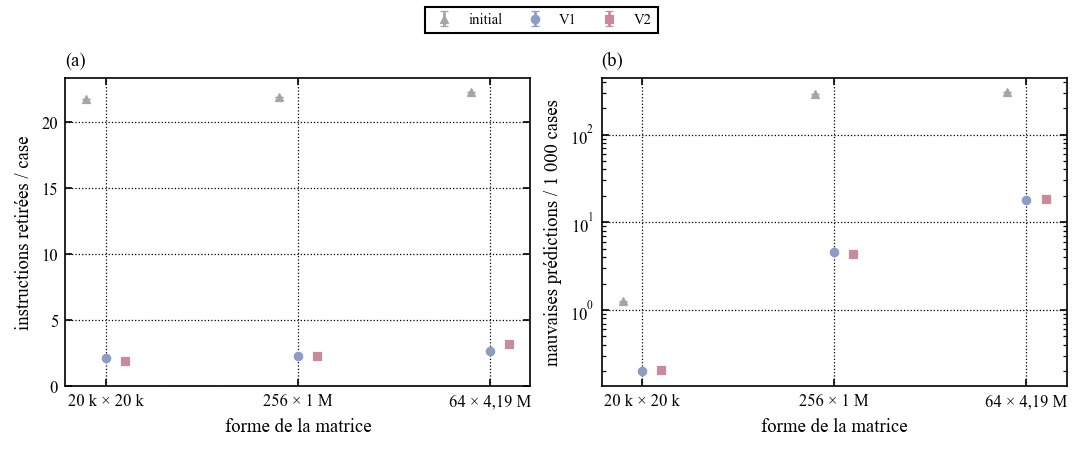

In [6]:
# Compteurs du calcul à un cœur. La valeur disponible est ramenée à une case.
pm_g = me_perf[me_perf.threads.eq(1)]
pm_fig, pm_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
pm_events = [("instructions", 1, "instructions retirées / case"),
             ("branch-misses", 1000, "mauvaises prédictions / 1 000 cases")]
for pm_j, (pm_event, pm_scale, pm_title) in enumerate(pm_events):
    for pm_i, (pm_v, pm_label) in enumerate([("baseline", "initial"), ("v1", "V1"), ("v2", "V2")]):
        pm_sub = pm_g[pm_g.event.eq(pm_event) & pm_g.variant.eq(pm_v)]
        pm_val = pm_sub.groupby("case").per_cell.agg(["median", "min", "max"]).reindex(ab_cases) * pm_scale
        pm_ax[pm_j].errorbar(me_x + .1*(pm_i-1), pm_val["median"], fmt=["^", "o", "s"][pm_i],
                             color=[COLORS[4], COLORS[0], COLORS[1]][pm_i], capsize=2,
                             yerr=[pm_val["median"]-pm_val["min"], pm_val["max"]-pm_val["median"]],
                             label=pm_label)
    pm_ax[pm_j].set_xticks(me_x, ab_cases.values())
    pm_ax[pm_j].set(xlabel="forme de la matrice", ylabel=pm_title)
    if pm_j == 1:
        pm_ax[pm_j].set_yscale("log")
    else:
        pm_ax[pm_j].set_ylim(bottom=0)
label_panels(pm_ax)
legend_above(pm_fig, pm_ax, ncol=3)
nv_save(pm_fig, "05_cout_instructions")

*Figure 005.* Appels après chauffe sur un cœur EPYC. (a) Instructions retirées par case. (b) Mauvaises prédictions de branchement pour 1 000 cases, en échelle logarithmique. Chaque intervalle relie les valeurs de deux captures perf séparées.

À un cœur sur le rectangle de 256 lignes, les instructions passent de 21,89 par case à 2,26 entre la version initiale et V1. Les mauvaises prédictions passent de 291 à 4,5 pour 1 000 cases et les cycles de 9,46 à 1,59 par case. Pour le carré, les mauvaises prédictions sont déjà rares dans la version initiale (1,3 pour 1 000 cases) et V1 réduit encore le nombre d’instructions de 21,76 à 2,13 par case. Le diagnostic de GCC confirme des vecteurs de 32 octets dans cette boucle.

**Synthèse.** L’amélioration de V1 apparaît dans les instructions pour les trois formes. Le poids des mauvaises prédictions dépend de la forme de l’entrée. Ces données ne donnent pas le temps dû à chaque défaut de prédiction.

<sub>Code : [récurrence et boucle intérieure](../src/dp.cpp), [pilote perf](../bench/profile_cpu.py), [diagnostic de GCC](../results/profile/cpu/vectorization.csv), [comptages en espace utilisateur](../results/profile/cpu/counters.csv).</sub>

## 6. Amortir le lancement des noyaux CUDA

Dans la version initiale (A), le CPU lance un noyau par ligne. La variante retenue (B) avance de huit lignes par tuile en mémoire partagée. Chaque bloc recalcule un halo à gauche pour pouvoir progresser sans lire le travail d’un bloc voisin. Ses 256 fils couvrent 1 024 colonnes lorsque la grille garde au moins deux blocs par multiprocesseur, sinon 256. Lorsque la dépendance gauche dépasse 64 colonnes, ou que le chemin d’alignement est demandé, le programme utilise le noyau par ligne. La mesure à froid démarre dans un processus neuf. Les mesures à chaud démarrent après un premier appel vérifié dans ce même processus. Le retour du dernier coût sur l’hôte garantit que le GPU a terminé. Dans les deux cas, le temps couvre aussi le calcul de l’index, les allocations et les transferts. [NVIDIA, mesure du temps CPU et GPU](https://docs.nvidia.com/cuda/cuda-c-best-practices-guide/index.html#timing)

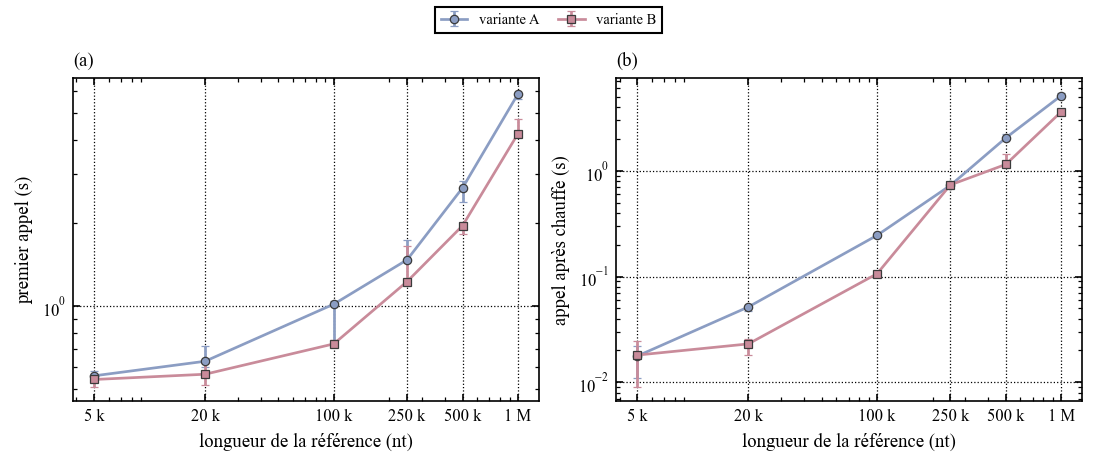

In [7]:
# Appels froids et chauds sur les mêmes FASTA, hors capture Nsight.
gp_dir = PROF / "gpu/838170"
gp_raw = nv_csv(gp_dir / "trials.csv")
gp_truth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(.02) & nv_pair.rep.eq(1)]
assert set(gp_raw.variant) == {"baseline", "candidate"} and gp_raw.trace.eq(0).all()
gp_ref = gp_truth.set_index("length").distance
assert gp_raw.groupby("input").distance.nunique().eq(1).all()
gp_comparable = gp_raw[gp_raw.m.isin(gp_ref.index)]
assert gp_comparable.distance.eq(gp_comparable.m.map(gp_ref)).all()
assert gp_raw.groupby(["input", "variant", "mode"]).run.nunique().eq(3).all()
gp_counts = gp_raw.groupby(["input", "variant", "mode", "run"]).size()
assert gp_counts.xs("cold", level="mode").eq(1).all() and gp_counts.xs("warm", level="mode").eq(3).all()
assert gp_raw.groupby("input").device_bytes.nunique().eq(1).all()
gp_hold = nv_csv(PROF / "gpu/838173/trials.csv")
gp_htruth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(.10) & nv_pair.rep.eq(1)]
assert gp_hold.distance.eq(gp_hold.m.map(gp_htruth.set_index("length").distance)).all()
gp_groups = ["m", "variant", "mode", "run"]
# Une mesure froide et une médiane des mesures chaudes par processus.
gp_lineage = pd.concat({"tuiles fixes, 2 %": nv_csv(PROF / "gpu/838161/trials.csv"),
                        "largeur adaptative, 2 %": gp_raw, "largeur adaptative, 10 %": gp_hold},
                       names=["expérience"]).reset_index(level=0)
gp_runs = gp_lineage.groupby(["expérience", *gp_groups], as_index=False).seconds.median()
gp_medians = gp_runs.groupby(["expérience", "m", "mode", "variant"]).seconds.median().unstack()
gp_medians["gain"] = gp_medians["baseline"] / gp_medians["candidate"]
gp_run = gp_runs[gp_runs["expérience"].eq("largeur adaptative, 2 %")]
gp_fig, gp_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
for gp_k, (gp_variant, gp_label) in enumerate([("baseline", "A"), ("candidate", "B")]):
    for gp_i, gp_mode in enumerate(["cold", "warm"]):
        gp_sub = gp_run[gp_run.variant.eq(gp_variant) & gp_run["mode"].eq(gp_mode)].set_index("m")
        nv_band(gp_ax[gp_i], gp_sub.seconds, COLORS[gp_k], "variante " + gp_label, marker="os"[gp_k])
for gp_axis, gp_label in zip(gp_ax, ["premier appel (s)", "appel après chauffe (s)"]):
    gp_axis.set(xscale="log", yscale="log", xlabel="longueur de la référence (nt)", ylabel=gp_label)
    gp_sizes = np.sort(gp_run.m.unique())
    gp_ticks = {5000: "5 k", 20000: "20 k", 100000: "100 k", 250000: "250 k", 500000: "500 k", 1000000: "1 M"}
    gp_axis.set_xticks(gp_sizes, [gp_ticks[v] for v in gp_sizes])
label_panels(gp_ax)
legend_above(gp_fig, gp_ax, ncol=2)
nv_save(gp_fig, "06_variantes_gpu")

*Figure 006.* Coût d’un alignement sur GH200 à 2 % d’erreur. Le pilote reprend la première paire des quatre tailles du projet et ajoute deux paires intermédiaires. (a) Premier appel dans chacun des trois processus. (b) Médiane des trois appels suivants dans chaque processus. Les points et les barres résument les trois processus (médiane et extrêmes).

Le premier essai de tuiles fixes (job 838161) donnait 2,70× de gain à chaud sur 5 000 bases et 0,98× sur un million. Dans le job 838170, la largeur adaptative ramène le temps chaud à un million de 5,14 à 3,62 s (1,42×). À froid, les temps passent de 5,85 à 4,20 s (1,39×). Dans le contrôle indépendant à 10 % (job 838173), les gains à chaud valent 2,42×, 3,22× et 2,38× à 5, 20 et 100 milliers de bases. À un million, le temps passe de 5,15 à 3,64 s (1,41×). Le même gain à chaud dans le job 838170 vaut 2,24× à 20 000 et 1,78× à 500 000 bases. Les tampons globaux explicitement alloués valent 22,9 Mio à un million pour les deux versions. Ce total exclut la mémoire partagée par bloc et le contexte CUDA.

**Synthèse.** La largeur adaptative améliore le temps sur quatre des six tailles à chaud. Les médianes des processus sont proches à 5 000 et 250 000 bases (rapports 0,98 et 0,99). La dispersion des trois processus est particulièrement forte sur la petite paire. [Tuiles fixes, 2 %](../results/profile/gpu/838161/trials.csv) · [Contrôle indépendant, 10 %](../results/profile/gpu/838173/trials.csv).

<sub>Code : [noyaux CUDA](../src/cuda.cu), [pilote de mesure](../bench/profile_gpu.cu), [essais CUDA](../results/profile/gpu/838170/trials.csv).</sub>

## 7. Lire la trace Nsight Systems

Une capture séparée, exclue des chronométrages A/B, encadre un appel après chauffe sur la paire de 5 000 bases à 2 %. La trace distingue les durées des appels à l’API sur l’hôte et celles des noyaux ou transferts sur l’accélérateur. Les lignes de temps peuvent se recouvrir. Additionner ces trois totaux surestimerait le temps de bout en bout. [NVIDIA, profilage d’une fenêtre d’exécution](https://docs.nvidia.com/nsight-systems/UserGuide/index.html#focused-profiling)

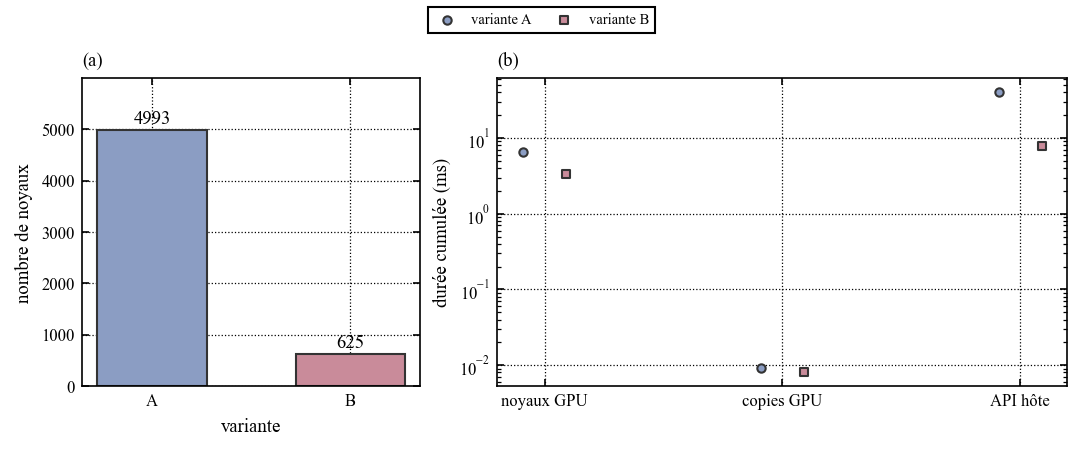

In [8]:
# Comptage des noyaux et temps par domaine de mesure (exports Nsight du job GPU).
ns_rows = []
for ns_variant in ("baseline", "candidate"):
    ns_k = nv_csv(gp_dir / f"{ns_variant}_cuda_gpu_kern_sum.csv")
    ns_a = nv_csv(gp_dir / f"{ns_variant}_cuda_api_sum.csv")
    ns_t = nv_csv(gp_dir / f"{ns_variant}_cuda_gpu_mem_time_sum.csv")
    ns_rows.append({"variante": ns_variant, "noyaux": ns_k.Instances.sum(),
                    "noyaux GPU": ns_k["Total Time (ns)"].sum() / 1e6,
                    "copies GPU": ns_t["Total Time (ns)"].sum() / 1e6,
                    "API hôte": ns_a["Total Time (ns)"].sum() / 1e6})
ns_tot = pd.DataFrame(ns_rows).set_index("variante")
ns_fig, ns_ax = plt.subplots(1, 2, figsize=(7.1, 2.9), width_ratios=[.8, 1.35])
ns_colors = COLORS[:2]
ns_x = np.arange(3)
for ns_i, (ns_variant, ns_label) in enumerate([("baseline", "A"), ("candidate", "B")]):
    ns_count = int(ns_tot.loc[ns_variant, "noyaux"])
    ns_ax[0].bar(ns_i, ns_count, width=.55, color=ns_colors[ns_i], edgecolor="0.2")
    ns_ax[0].annotate(str(ns_count), (ns_i, ns_count), xytext=(0, 3), textcoords="offset points", ha="center")
    ns_vals = ns_tot.loc[ns_variant, ["noyaux GPU", "copies GPU", "API hôte"]]
    ns_ax[1].scatter(ns_x + (ns_i - .5) * .18, ns_vals, color=ns_colors[ns_i], marker="os"[ns_i],
                     edgecolor="0.2", label="variante " + ns_label, zorder=3)
ns_ax[0].set_xticks([0, 1], ["A", "B"])
ns_ax[0].set(ylabel="nombre de noyaux", xlabel="variante", ylim=(0, ns_tot.noyaux.max()*1.2))
ns_ax[1].set_xticks(ns_x, ["noyaux GPU", "copies GPU", "API hôte"])
ns_ax[1].set(yscale="log", ylabel="durée cumulée (ms)")
label_panels(ns_ax)
legend_above(ns_fig, ns_ax, ncol=2)
nv_save(ns_fig, "07_trace_cuda")

*Figure 007.* Un appel après chauffe sur 5 000 × 4 992 bases, sous Nsight Systems. (a) Nombre de noyaux exécutés. (b) Durées cumulées à l’intérieur de chaque catégorie de trace, en millisecondes sur une échelle logarithmique.

Sur cette paire, A lance un noyau d’initialisation et 4 992 noyaux de ligne. B lance le même noyau d’initialisation et 624 noyaux de tuile. Le temps cumulé des noyaux passe de 6,46 à 3,34 ms, celui des appels hôtes à `cudaLaunchKernel` de 12,21 à 1,53 ms. Les copies sur le GPU totalisent environ 9 et 8 µs. La capture ralentit elle-même certains appels et ne permet pas de prévoir à elle seule le rapport de temps de bout en bout de la figure 006.

**Synthèse.** Le nombre de noyaux est divisé par huit sur cette entrée. Nsight Compute a renvoyé `ERR_NVGPUCTRPERM` pour les deux variantes. Aucun taux de défaut de cache GPU, débit matériel DRAM ni taux d’occupation mesuré ne se déduit de cette trace. [Diagnostic des compteurs GPU](../results/profile/gpu/838170/candidate-counters.txt).

<sub>Code : [collecte Nsight Systems](../bench/profile_gpu.sbatch), [résumés API, noyaux et transferts](../results/profile/gpu/838170/).</sub>

## 8. Réutiliser les tampons CUDA entre les alignements

L’expérience mesure le coût des allocations CUDA pour une collection, hors de Nsight. Le premier mode réserve et libère les deux tableaux CUDA pour chaque paire. Le second conserve les deux tampons d’une paire à l’autre, tant que leurs tailles correspondent exactement. Le chronomètre couvre tout le lot après chauffe, y compris la première allocation et la dernière libération. Le calcul des distances de référence avec edlib se fait avant le chronométrage. À chaque répétition, les deux modes traitent le même FASTA, dans un ordre alterné.

Trois lots synthétiques contiennent des séquences de même longueur. Le quatrième regroupe 64 phages φX174, dont les longueurs varient. On compte les appels physiques à `cudaMalloc` et `cudaFree`, y compris la libération à la fin du lot. Les mesures de mémoire portent sur les deux tableaux explicites sur GPU. [Pilote des lots et ordre des essais](../bench/allocator_measure.py)

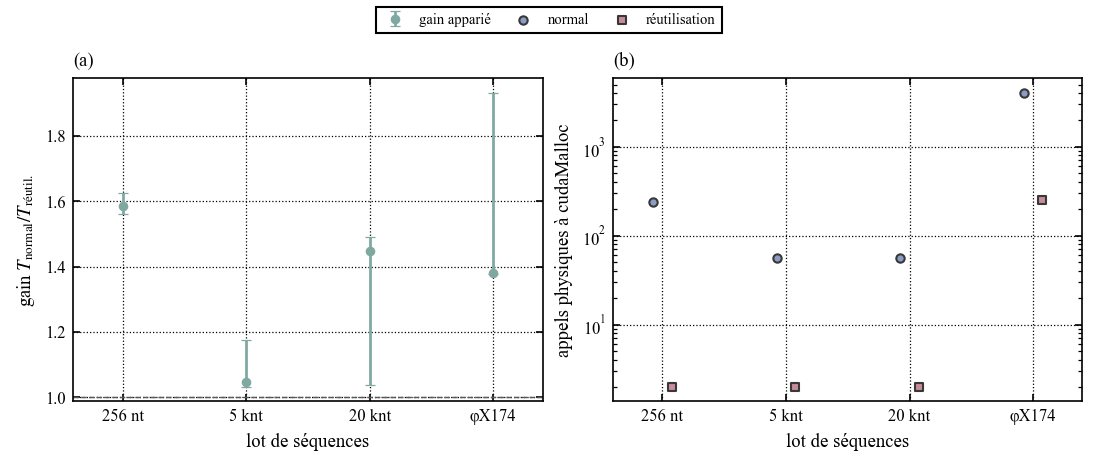

In [9]:
# Comparaison appariée sur des lots contrôlés, hors capture Nsight.
pool_alloc = nv_csv(RES / "allocator/trials.csv")
assert set(pool_alloc["mode"]) == {"normal", "reuse"}
assert set(pool_alloc["case"]) == {"fixed-256", "fixed-5000", "fixed-20000", "phix174"}
assert pool_alloc.groupby(["case", "trial"]).size().eq(2).all()
assert pool_alloc.groupby(["case", "mode"]).trial.nunique().eq(3).all()
for pool_column in ["distance_fnv64", "input_sha256", "pairs", "peak_live_bytes"]:
    assert pool_alloc.groupby("case")[pool_column].nunique().eq(1).all()
assert pool_alloc.malloc_calls.eq(pool_alloc.free_calls).all()
assert pool_alloc.groupby("case").peak_reserved_bytes.nunique().eq(1).all()
assert pool_alloc.malloc_calls.add(pool_alloc.reuse_hits).eq(2 * pool_alloc.pairs).all()
pool_ab = pool_alloc.pivot(index=["case", "trial"], columns="mode", values="seconds")
pool_alloc_stats = pool_alloc.groupby(["case", "mode"])[["seconds", "malloc_calls", "peak_reserved_bytes"]].median()
pool_cases = ["fixed-256", "fixed-5000", "fixed-20000", "phix174"]
pool_x = np.arange(len(pool_cases))
pool_labels = ["256 nt", "5 knt", "20 knt", "φX174"]
pool_fig, pool_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
pool_r = (pool_ab.normal / pool_ab.reuse).groupby("case").agg(["median", "min", "max"]).reindex(pool_cases)
pool_ax[0].errorbar(pool_x, pool_r["median"], yerr=[pool_r["median"]-pool_r["min"], pool_r["max"]-pool_r["median"]],
                    fmt="o", color=COLORS[2], capsize=2.5, label="gain apparié")
pool_ax[0].axhline(1, **GUIDE)
pool_ax[0].set(ylabel=r"gain $T_{\mathrm{normal}}/T_{\mathrm{réutil.}}$", xlabel="lot de séquences")
for pool_i, (pool_mode, pool_label) in enumerate([("normal", "normal"), ("reuse", "réutilisation")]):
    pool_c = pool_alloc_stats.xs(pool_mode, level="mode").reindex(pool_cases)
    pool_ax[1].scatter(pool_x + (pool_i-.5)*.15, pool_c.malloc_calls, marker="os"[pool_i], color=COLORS[pool_i],
                       edgecolor="0.22", label=pool_label, zorder=3)
pool_ax[1].set(yscale="log", ylabel="appels physiques à cudaMalloc", xlabel="lot de séquences")
for pool_axis in pool_ax:
    pool_axis.set_xticks(pool_x, pool_labels)
    pool_axis.set_xlim(-.40, 3.40)
label_panels(pool_ax)
legend_above(pool_fig, pool_ax, ncol=3)
nv_save(pool_fig, "08_allocations_cuda")

*Figure 008.* (a) Rapport apparié des temps du lot complet, avec médiane et extrêmes des trois répétitions. Une valeur supérieure à un indique que la réutilisation réduit le temps. (b) Nombre d’appels physiques à `cudaMalloc` par lot, sur une échelle logarithmique. Chaque mode libère tous ses tableaux avant la fin du chronométrage.

Les 120 alignements de séquences de 256 bases demandent 240 appels physiques à `cudaMalloc` en mode normal et deux avec réutilisation. Le gain apparié médian atteint 1,59. Sur 28 alignements de 5 000 bases, la même réduction de 56 à deux appels ne donne que 1,05 de gain, contre 1,45 sur le lot de 20 000 bases. Sur ces trois lots, le pic des tableaux reste identique dans les deux modes. Il va de 6 168 à 480 024 octets selon la longueur.

Dans un essai distinct, trois paires de processus neufs exécutent la commande complète sur φX174. Le temps médian passe de 23,60 à 9,40 s, avec un gain apparié médian de 2,48. Les six matrices sont identiques à celle d’edlib.

**Synthèse.** Pour les 2 016 distances de φX174, le nombre d’allocations passe de 4 032 à 250 et le temps médian du lot passe de 11,80 à 8,55 s. Le gain apparié médian vaut 1,38 et le pic explicite reste de 150 892 octets. Les deux modes reproduisent la même matrice qu’edlib. Sur ces données, les différences de temps dépendent du lot autant que du nombre d’allocations évitées.

<sub>Code : [sonde des allocations](../bench/allocator_probe.cu), [comparaison des deux modes](../bench/allocator_measure.py), [essais et empreintes](../results/allocator/trials.csv), [temps de la commande complète](../results/allocator/production.csv).</sub>

## 9. Porter la récurrence avec Kokkos

Un espace d’exécution Kokkos choisit où se déroule une boucle. Le même programme source peut soumettre une ligne de NvPD à OpenMP sur CPU ou à CUDA sur GPU. Dans ce portage, une `RangePolicy` distribue les colonnes de chaque ligne et une barrière `fence` précède la récupération du score. Sur GPU, le noyau Kokkos suit la récurrence ligne par ligne, tandis que la version CUDA native peut regrouper huit lignes en tuiles. Un processus neuf effectue un appel de chauffe puis un appel chronométré, allocations et transferts compris. Les deux implémentations alternent leur ordre entre les trois répétitions sur les mêmes entrées. Le GPU utilise CUDA 12.6.3 et l’espace d’exécution `Kokkos::Cuda`. [Boucles parallèles Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/parallel_for.html) · [Synchronisation Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/fence.html)

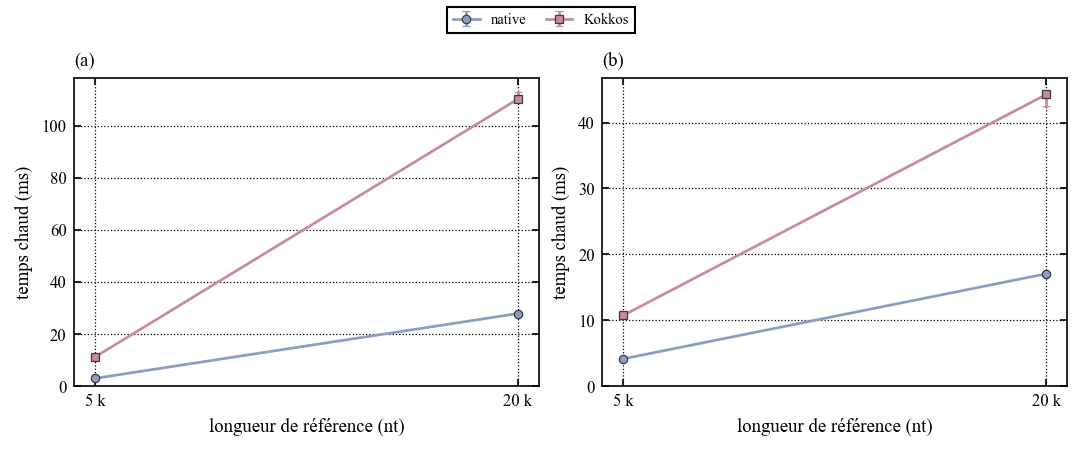

In [10]:
# Coût du portage Kokkos par rapport à l'implémentation native de chaque cible.
ko_raw = nv_csv(RES / "kokkos/timings.csv")
assert ko_raw.distance.eq(ko_raw.reference_distance).all()
ko_fig, ko_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for ko_i, (ko_target, ko_native) in enumerate([("cpu", "nvpd-omp"), ("gpu", "nvpd-cuda")]):
    ko_sub = ko_raw[ko_raw.target.eq(ko_target)]
    ko_sub = ko_sub[ko_sub.threads.eq(ko_sub.threads.max())]
    assert set(ko_sub.algorithm) == {ko_native, "nvpd-kokkos"}
    assert set(ko_sub.m) == {5000, 20000}
    assert ko_sub.groupby("m").input_sha256.nunique().eq(1).all()
    assert ko_sub.groupby(["input_sha256", "algorithm"]).trial.nunique().eq(3).all()
    for ko_j, (ko_alg, ko_label) in enumerate([(ko_native, "native"), ("nvpd-kokkos", "Kokkos")]):
        ko_t = ko_sub[ko_sub.algorithm.eq(ko_alg)].set_index("m").seconds * 1000
        nv_band(ko_ax[ko_i], ko_t, COLORS[ko_j], ko_label, marker="os"[ko_j])
    ko_ax[ko_i].set(ylabel="temps chaud (ms)", xlabel="longueur de référence (nt)", ylim=(0, None))
    ko_len = sorted(ko_sub.m.unique())
    ko_ax[ko_i].set_xticks(ko_len, [f"{v/1000:g} k" for v in ko_len])
label_panels(ko_ax)
legend_above(ko_fig, ko_ax, ncol=2)
nv_save(ko_fig, "09_portage_kokkos")

*Figure 009.* Temps d’un appel de coût seul après chauffe. Chaque panneau compare les mêmes entrées pour une cible matérielle. (a) Huit cœurs EPYC. (b) Un GH200, quatre fils hôtes. Les points donnent les médianes des trois processus et les barres leur étendue.

À 20 000 bases sur huit cœurs EPYC, les médianes valent 27,90 ms avec la boucle OpenMP native et 110,22 ms avec Kokkos OpenMP. Sur GH200, CUDA natif demande 17,06 ms et Kokkos CUDA 44,27 ms. À 5 000 bases, les deux temps GPU sont de 4,15 et 10,75 ms. À 20 000 bases, les deux versions GPU réservent 480 024 octets pour les mêmes tableaux de scores et d’index.

**Synthèse.** Kokkos 4.5.01 exécute la même récurrence sur les deux architectures et retrouve les scores d’edlib dans les 36 essais. Les versions natives sont plus rapides sur les deux longueurs. Ce rapport inclut les choix de boucle et de lancement propres à chaque implémentation. [Contrôles du coût, du chemin et des matrices](../results/kokkos/checks.csv).

<sub>Code : [pilote Kokkos](../bench/kokkos_measure.py), [données de la comparaison](../results/kokkos/timings.csv).</sub>

## 10. Distribuer une paire ou une collection entre deux nœuds

Pour aligner une seule paire, chaque rang MPI conserve une bande de colonnes. À chaque ligne, il partage deux scores entiers avec tous les rangs pour résoudre les dépendances qui traversent une frontière. L’expérience affecte 24 rangs de huit fils OpenMP à chaque nœud. Pour une collection, le programme distribue des paires indépendantes entre les rangs puis entre les fils OpenMP. Une seule réduction finale réunit les distances. Un nœud compte 192 cœurs actifs et deux nœuds en comptent 384 avec la même disposition des équipes. [Implémentation distribuée](../src/mpi.cpp) · [Norme MPI, opérations collectives](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

Les mesures à un et deux nœuds utilisent les mêmes séquences dans une réservation exclusive. Chaque essai commence après une barrière, puis le pilote conserve la durée du rang le plus lent. Le rapport $S=T_1/T_2$ donne le gain du second nœud. L’efficacité de ce doublement est $S/2$. Les trois répétitions suivent un appel de chauffe.

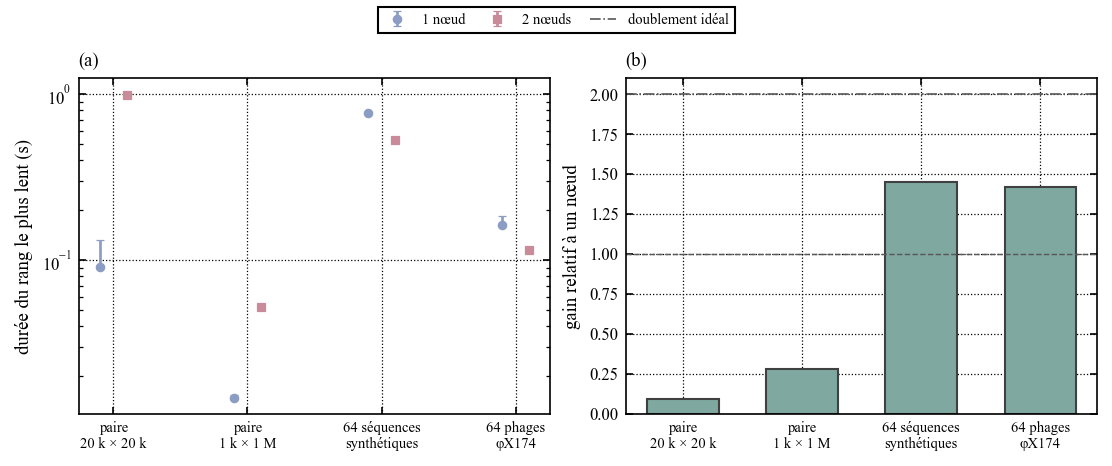

In [11]:
# Mesure du passage de un à deux nœuds complets (results/mpi/838226/trials.csv).
mp_raw = nv_csv(RES / "mpi/838226/trials.csv")
assert mp_raw.groupby("case").input_sha256.nunique().eq(1).all()
assert mp_raw.groupby("case").distance_or_matrix_sha256.nunique().eq(1).all()
assert mp_raw.groupby(["case","nodes"]).trial.nunique().eq(3).all()
assert mp_raw.assigned_workers.eq(mp_raw.step_cores).all()
assert mp_raw.sampled_physical_cores.eq(mp_raw.nodes * 192).all()
assert set(mp_raw.oracle_algorithm) == {"edlib"}
mp_cases = {"square":"paire\n20 k × 20 k", "wide":"paire\n1 k × 1 M",
            "synthetic64":"64 séquences\nsynthétiques", "phix64":"64 phages\nφX174"}
mp_times = mp_raw.groupby(["case","nodes"]).seconds.agg(["median","min","max"])
mp_x = np.arange(len(mp_cases))
mp_fig, mp_ax = plt.subplots(1, 2, figsize=(7.3, 3.0))
for mp_i, mp_nodes in enumerate([1, 2]):
    mp_g = mp_times.xs(mp_nodes,level="nodes").reindex(mp_cases)
    mp_ax[0].errorbar(mp_x + .10*(2*mp_i-1), mp_g["median"], fmt="os"[mp_i],
                      yerr=[mp_g["median"]-mp_g["min"], mp_g["max"]-mp_g["median"]],
                      color=COLORS[mp_i], capsize=2, label=f"{mp_nodes} nœud" + ("s" if mp_nodes==2 else ""))
mp_one = mp_times.xs(1,level="nodes").reindex(mp_cases)["median"]
mp_two = mp_times.xs(2,level="nodes").reindex(mp_cases)["median"]
mp_ax[1].bar(mp_x, mp_one/mp_two, width=.6, color=COLORS[2], edgecolor="0.25")
mp_ax[1].axhline(1, **GUIDE)
mp_ax[1].axhline(2, color="0.35", lw=.8, ls="-.", label="doublement idéal")
for mp_axis in mp_ax:
    mp_axis.set_xticks(mp_x, mp_cases.values(), fontsize=7)
mp_ax[0].set(yscale="log", ylabel="durée du rang le plus lent (s)")
mp_ax[1].set(ylabel="gain relatif à un nœud", ylim=(0, None))
label_panels(mp_ax)
legend_above(mp_fig, mp_ax, ncol=3)
nv_save(mp_fig, "10_echelle_mpi")

*Figure 010.* Même problème sur un et deux nœuds. (a) Médiane et extrêmes des trois durées par configuration. (b) Rapport des deux médianes. La ligne horizontale à un marque l’égalité des temps. Les paires isolées partagent chaque ligne d’une matrice, les collections répartissent des matrices indépendantes.

Sur la paire presque carrée, passer de 192 à 384 cœurs porte le temps de 91 à 990 ms. Chaque alignement échange les frontières 20 000 fois. La paire large effectue 1 024 échanges et passe de 14,8 à 52,6 ms. La forte hausse temporelle coïncide avec la communication inter-nœuds, mais le chronométrage global ne sépare pas le temps des collectives de celui du calcul.

Sur les 2 016 paires synthétiques, le temps médian passe de 0,764 à 0,528 s (1,45×). Sur les 64 phages, il passe de 0,162 à 0,115 s (1,42×). Pour les quatre cas, la distance scalaire ou l’empreinte de la matrice coïncide avec celle d’edlib et les contrôles d’affinité trouvent bien 192 puis 384 cœurs physiques.

**Synthèse.** Les matrices de paires indépendantes atteignent 72 % et 71 % d’efficacité sur deux nœuds. Pour une paire isolée, les échanges par ligne conduisent ici à des gains inférieurs à un.

<sub>Code : [distribution des colonnes et des paires](../src/mpi.cpp), [affinité et allocation](../bench/mpi.sbatch), [comparaison avec edlib](../bench/mpi_benchmark.py), [essais MPI](../results/mpi/838226/trials.csv).</sub>

## 11. Deux fenêtres du chromosome 21 et un contrôle de 45 millions de bases

La chaîne de correspondance hg38–hs1 permet de retrouver dans l’assemblage T2T-CHM13 les bornes de deux intervalles du chromosome 21 de GRCh38. Les positions sont indexées depuis zéro et la borne de fin est exclue. Les fenêtres GRCh38 commencent toutes les deux à 34 000 000 et se terminent à 36 000 000 et 38 000 000. La première est donc incluse dans la seconde. La chaîne sert à choisir les intervalles, puis chaque algorithme calcule une distance globale sur les chaînes FASTA complètes de la paire. [Manifeste et coordonnées](../results/human/manifest.tsv) · [Chaîne de correspondance UCSC](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/liftOver/hg38ToHs1.over.chain.gz)

Le contrôle utilise le chromosome 21 entier de T2T-CHM13, long de 45 090 682 bases, face à une copie où le générateur insère 64 lettres. L’écart de longueur impose au moins 64 opérations et les 64 insertions donnent un chemin de ce coût. La distance est donc exactement 64. Ce contrôle mesure le cas d’un très long alignement presque identique. Il porte sur des modifications dispersées d’un même assemblage.

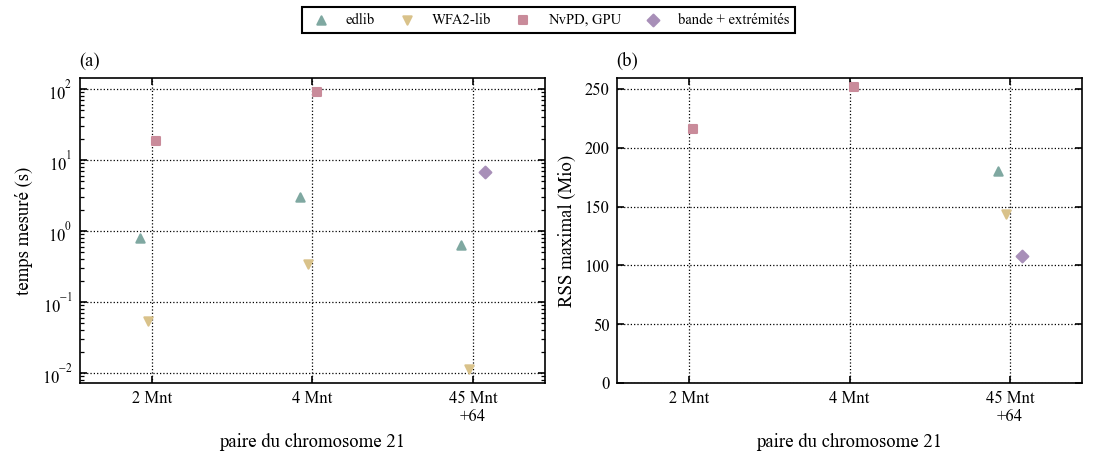

In [12]:
# Intervalles homologues et contrôle synthétique sur fond de chromosome réel.
hu_manifest = pd.read_csv(RES / "human/manifest.tsv", sep="\t").set_index("case")
hu_raw = nv_csv(RES / "human/838220/trials.csv")
hu_ok = hu_raw[hu_raw.status.eq("ok")].copy()
assert hu_ok.groupby("case").distance.nunique().eq(1).all()
assert hu_ok.groupby(["case", "algorithm"]).trial.nunique().eq(2).all()
assert hu_ok.input_sha256.eq(hu_ok.case.map(hu_manifest.sha256)).all()
assert (hu_ok.m == hu_ok.case.map(hu_manifest.m)).all() and (hu_ok.n == hu_ok.case.map(hu_manifest.n)).all()
assert hu_ok.loc[hu_ok.case.eq("chr21-full-insert64"), "distance"].eq(64).all()
hu_spot = pd.read_json(RES / "kokkos/human.json", typ="series")
assert hu_spot.distance == hu_spot.reference_distance == hu_ok.loc[hu_ok.case.eq("chr21-2m"), "distance"].iloc[0]
assert hu_spot.input_sha256 == hu_manifest.loc["chr21-2m", "sha256"]
hu_order = ["chr21-2m", "chr21-4m", "chr21-full-insert64"]
hu_fig, hu_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
# Un point par algorithme et cas mesuré. Une absence de point reste visible.
for hu_i, hu_alg in enumerate(hu_ok.algorithm.unique()):
    hu_g = hu_ok[hu_ok.algorithm.eq(hu_alg)].groupby("case")
    hu_t = hu_g.seconds.median().reindex(hu_order)
    hu_rss = hu_g.peak_rss_kib.max().reindex(hu_order).replace(0, np.nan) / 1024
    hu_label, hu_col, hu_mark = (("bande + extrémités", COLORS[5], "D") if hu_alg == "banded-trim"
                                  else nv_methods[hu_alg])
    hu_pos = np.arange(3) + .05*(hu_i - (hu_ok.algorithm.nunique()-1)/2)
    hu_ax[0].scatter(hu_pos, hu_t, color=hu_col, marker=hu_mark, label=hu_label, zorder=3)
    hu_ax[1].scatter(hu_pos, hu_rss, color=hu_col, marker=hu_mark, label=hu_label, zorder=3)
for hu_axis in hu_ax:
    hu_axis.set_xticks(range(3), ["2 Mnt", "4 Mnt", "45 Mnt\n+64"])
    hu_axis.set_xlim(-.45, 2.45)
hu_ax[0].set(yscale="log", ylabel="temps mesuré (s)", xlabel="paire du chromosome 21")
hu_ax[1].set(ylabel="RSS maximal (Mio)", xlabel="paire du chromosome 21", ylim=(0, None))
label_panels(hu_ax)
legend_above(hu_fig, hu_ax, ncol=4)
nv_save(hu_fig, "11_chromosome21")

*Figure 011.* Calcul global sur des fenêtres homologues de deux assemblages (2 et 4 Mnt) et sur une copie du chromosome entier modifiée en 64 positions. (a) Durée médiane des deux essais. (b) Plus grand pic de mémoire résidente hôte des deux processus. Les RSS nuls renvoyés par le système sont laissés manquants. Chaque point correspond à une méthode exécutée sur la paire.

Les deux fenêtres donnent 5 599 et 12 482 éditions. À 4 Mnt, les deux exécutions de NvPD sur GPU demandent 90,60 et 91,18 s. Les médianes de WFA2-lib et d’edlib valent 0,35 et 2,99 s sur le CPU Grace. Les portées gauches maximales de 290 et 622 colonnes dépassent le seuil de 64. Le noyau CUDA lit donc une ligne à la fois, y compris avec la version adaptative. À 4 Mnt, il réserve 91,6 Mio en mémoire globale, pour un pic de RSS hôte de 252 Mio.

**Synthèse.** Les trois méthodes donnent le même score pour chacune des deux fenêtres naturelles. Sur le contrôle entier, edlib, WFA2-lib et la bande avec retrait des extrémités retrouvent 64. Le calcul WFA2-lib dure environ 0,011 s et le processus entier environ 0,48 s, lecture des 90 millions de bases comprise. Le job 838230 fournit un essai Kokkos CUDA indépendant sur la fenêtre de 2 Mnt. En un appel à froid, il retrouve 5 599 en 24,20 s, avec 48 030 336 octets de tableaux sur le GPU. La chaîne de compilation, l’allocation Slurm et l’initialisation diffèrent de la campagne native. [Mesure Kokkos sur la fenêtre de 2 Mnt](../results/kokkos/human.json).

<sub>Code : [préparation des séquences et des bornes](../scripts/human_reference.py), [mesures du chromosome 21](../results/human/838220/trials.csv).</sub>

## 12. Réduire le nombre de cases à calculer

La bande adaptative cherche d’abord un chemin de faible coût dans un couloir autour de la diagonale. Si le seuil est insuffisant, elle élargit le couloir jusqu’à certifier la distance globale. La variante `banded-trim` supprime aussi le préfixe et le suffixe communs avant ce calcul. En distance d’édition unitaire, deux lettres terminales identiques peuvent être appariées gratuitement. Supprimer ces extrémités conserve donc le score. Pour un seuil $k$, un chemin dont le coût est inférieur ou égal à $k$ reste dans $|i-j|\leq k$. L’implémentation double $k$ après chaque essai infructueux. Le temps gagné par le retrait des extrémités dépend de leur longueur. [Ukkonen, recherche à seuil](https://doi.org/10.1016/S0019-9958%2885%2980046-2)

Les exécutables locaux ont été compilés avec GCC 16.1. Les essais sont monothread, sans affinité CPU imposée sur le Mac. Chaque exécution lance un nouveau processus. L’ordre des cinq méthodes change à chaque répétition selon un générateur de graine fixée.

QuickEd utilise un schéma de borne puis d’alignement pour retrouver une distance exacte. A*PA2 associe programmation dynamique bit-parallèle, élargissement de bande et guidage heuristique. Ding et coll. proposent une autre famille d’algorithmes parallèles dont le travail dépend de la distance. Les gains publiés pour ces méthodes portent sur leurs propres jeux de séquences et machines. Sassy, de R. Beeloo et R. Groot Koerkamp, recherche les occurrences approchées d’un motif dans un texte. Le programme mm2-plus accélère le placement et l’alignement de segments par minimap2, une tâche différente du calcul d’un unique score global exact. [QuickEd, 2025](https://doi.org/10.1093/bioinformatics/btaf112) · [A*PA2, 2024](https://doi.org/10.4230/LIPIcs.WABI.2024.17) · [Ding et coll., 2023](https://doi.org/10.4230/LIPIcs.ESA.2023.40) · [Sassy, 2026](https://doi.org/10.1093/bioinformatics/btag244) · [mm2-plus, 2026](https://doi.org/10.1093/bioinformatics/btag083)

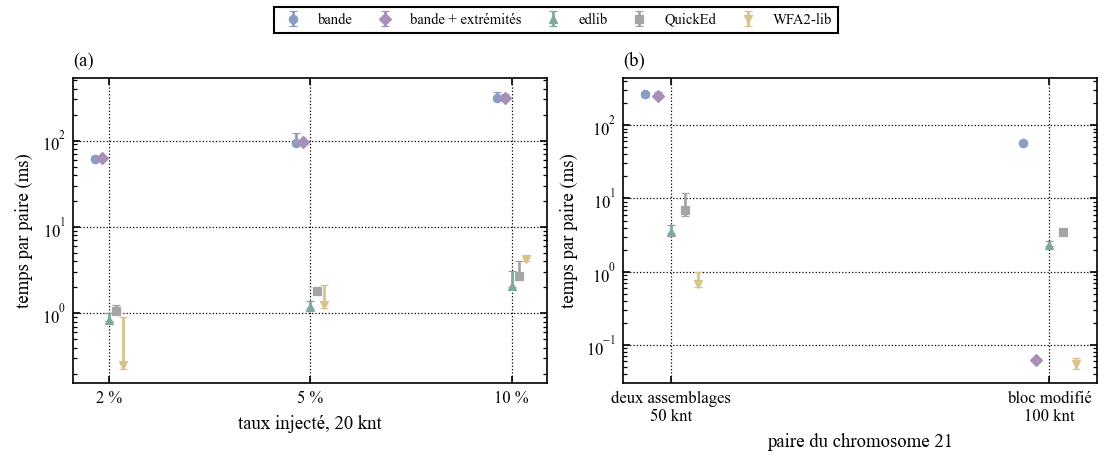

In [13]:
# Essais des méthodes exactes à entrée et machine identiques.
al_raw = nv_csv(RES / "alternatives/trials.csv")
al_ok = al_raw[al_raw.machine.eq("apple-m1-pro")]
assert al_ok.groupby(["case", "variant"]).trial.nunique().eq(5).all()
assert al_ok.groupby("case").sha256.nunique().eq(1).all()
assert al_ok.groupby("case").variant.nunique().eq(5).all()
assert al_ok.groupby(["machine", "case"]).distance.nunique().eq(1).all()
al_fig, al_ax = plt.subplots(1, 2, figsize=(7.3, 3.0))
al_method = {"banded": ("bande", COLORS[0], "o"), "banded-trim": ("bande + extrémités", COLORS[5], "D"),
             "edlib": nv_methods["edlib"], "quicked": ("QuickEd", COLORS[4], "s"), "wfa2": nv_methods["wfa2"]}
al_sets = [["20k-0.02", "20k-0.05", "20k-0.1"], ["chr21-50k", "chr21-center128"]]
for al_j, al_cases in enumerate(al_sets):
    for al_k, (al_v, (al_name, al_color, al_mark)) in enumerate(al_method.items()):
        al_t = (al_ok[al_ok.variant.eq(al_v)].groupby("case").seconds
                .agg(["median", "min", "max"]).reindex(al_cases) * 1000)
        al_x = np.arange(len(al_cases)) + (al_k-2)*.035
        al_ax[al_j].errorbar(al_x, al_t["median"], fmt=al_mark,
                             color=al_color, capsize=2, label=al_name,
                             yerr=[al_t["median"]-al_t["min"], al_t["max"]-al_t["median"]])
    al_ax[al_j].set(yscale="log", ylabel="temps par paire (ms)")
al_ax[0].set_xticks(range(3), ["2 %", "5 %", "10 %"])
al_ax[0].set_xlabel("taux injecté, 20 knt")
al_ax[1].set_xticks(range(2), ["deux assemblages\n50 knt", "bloc modifié\n100 knt"])
al_ax[1].set_xlabel("paire du chromosome 21")
label_panels(al_ax)
legend_above(al_fig, al_ax, ncol=5)
nv_save(al_fig, "12_methodes_exactes")

*Figure 012.* Méthodes exactes monothread sur Apple M1 Pro. (a) Première paire synthétique de 20 000 bases à trois taux. (b) Débuts sur 50 000 bases des intervalles homologues du chromosome 21, puis contrôle de 100 000 bases avec un bloc central modifié. Les points et les barres montrent la médiane et les extrêmes de cinq lancements à entrée identique.

Sur la paire de 50 000 bases issue des deux assemblages, les cinq méthodes retrouvent 698 éditions. WFA2-lib demande 0,68 ms, QuickEd 6,98 ms et la bande adaptative 266 ms. Les 125 scores de la figure concordent avec la référence indépendante. QuickEd 1.2 calcule un chemin en interne. Sur un autre test de répétitions décalées de 512 bases, son mode par défaut a renvoyé 954 pour une distance exacte de 128. Le pilote vérifie donc le score avec edlib après le chronométrage et signale chaque désaccord. Sur le contrôle de 100 000 bases, seuls les 128 caractères du centre ont été modifiés et la distance minimale vaut 72. Le retrait des extrémités réduit le calcul de la bande de 57,0 ms à 0,063 ms, tandis que WFA2-lib prend 0,055 ms.

**Synthèse.** Le gain du retrait des extrémités atteint environ 900× sur le contrôle où les changements sont regroupés, contre environ 1,07× sur les deux intervalles homologues de 50 000 bases. QuickEd fait partie des mesures. A*PA2, Ding et coll., Sassy et mm2-plus figurent dans la discussion bibliographique.

<sub>Code : [bande adaptative](../src/banded.cpp), [adaptateur QuickEd](../src/quicked_adapter.c), [vérification du score](../src/quicked_main.cpp), [tests sur les répétitions](../tests/quicked.py), [ordre des essais](../bench/alternatives.py), [mesures et configurations](../results/alternatives/trials.csv).</sub>

## Choix retenus

Sur les 2 016 paires de la collection de 64 génomes φX174, le job 838173 retrouve la même matrice avec les trois méthodes. Les temps muraux d’un lancement, comprenant lecture et écriture, sont 43,51 s sur le GPU avec NvPD, 54,3 ms avec edlib et 9,86 ms avec WFA2-lib sur quatre cœurs Grace. Les gains observés pour une longue paire se traduisent donc différemment quand un programme enchaîne ces petits alignements. [Empreintes des matrices et chronométrages](../results/profile/gpu/838173/cohort.csv).

**Synthèse.** Le projet retient la boucle vectorisée avec un index entier sur CPU et la largeur de tuile adaptative sur GPU. Pour les matrices, les nœuds MPI se partagent les alignements indépendants. Pour les deux fenêtres humaines étudiées, WFA2-lib donne le score exact en moins d’une seconde sur le CPU Grace.

<sub>Code : [sources C++ et CUDA](../src/), [protocole ROMEO](../bench/), [résultats bruts du profilage](../results/profile/).</sub>

[Projet CHPS1001](../README.md) · [Figures exportées](../figures/) · [Rapport PDF](../report/rapport.pdf)